<a href="https://colab.research.google.com/github/takumi-maker/dmd/blob/main/tredsignal_30_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Expanding Window WFO (SMA15) -> Trades: 56
Net TR: 1.4190, AR: 0.5891, MaxDD: 0.3730, CR: 1.5794


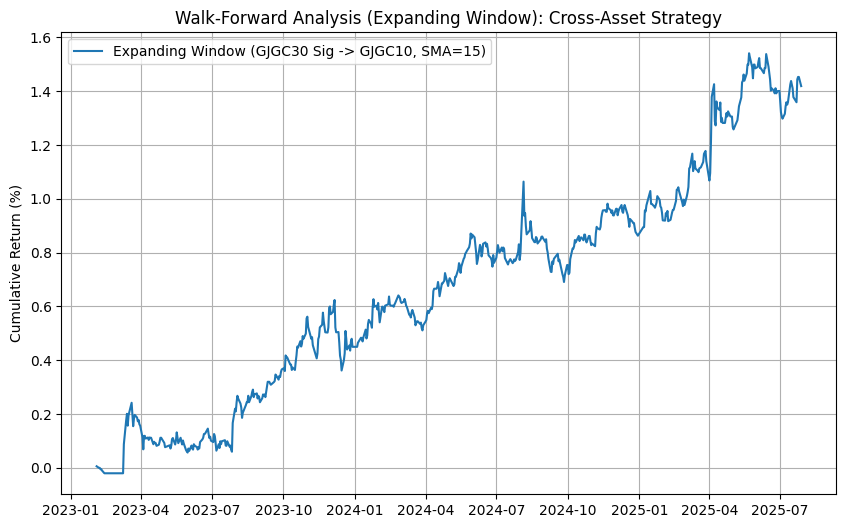

In [1]:
import pandas as pd
import numpy as np
from scipy.optimize import nnls
import matplotlib.pyplot as plt

# 1. データの読み込み
df = pd.read_csv('債券複利データセット3.csv')
df['Date'] = pd.to_datetime(df['Unnamed: 0'])
df.set_index('Date', inplace=True)

# 今回使用する対象データ（10年債と30年債）
prices_10 = df['GJGC10'].dropna().values
prices_30 = df['GJGC30'].dropna().values
dates = df['GJGC10'].dropna().index

# パラメータ設定
K = 30           # 考慮するラグ数
W_initial = 504  # 初期の学習期間 (2年 = 504営業日)
step = 21        # モデルの再学習を行う間隔 (1ヶ月 = 21営業日)
D = np.triu(np.ones((K, K))) # 単調減少制約のための行列
dp_30 = np.diff(prices_30)   # 30年債の階差データ

# アウトオブサンプル(OOS)シグナルの保存用配列
signals_oos = np.full(len(prices_30), np.nan)

# --- (準備) 初期期間のシグナル計算 ---
# SMAを計算するため、W_initialまでの期間も便宜上、初期モデルを使ってシグナルを埋めておきます
dp_train_init = dp_30[:W_initial]
T_obs_init = len(dp_train_init) - K
y_init = dp_train_init[K:]
X_init = np.zeros((T_obs_init, K))
for j in range(1, K + 1):
    X_init[:, j-1] = dp_train_init[K-j : len(dp_train_init)-j]
XD_ext_init = np.hstack((X_init @ D, np.ones((T_obs_init, 1)), -np.ones((T_obs_init, 1))))
z_ext_init, _ = nnls(XD_ext_init, y_init)
beta_init = D @ z_ext_init[:-2]

for t in range(K, W_initial):
    signals_oos[t] = np.sum(beta_init * dp_30[t-K:t][::-1])


# 2. ウォークフォワード (Expanding Window) でのモデル再学習とOOSシグナル生成
for t_start in range(W_initial, len(prices_30), step):
    t_end = min(t_start + step, len(prices_30))

    # 【最重要】Expanding Window: 最初の日から t_start までの全データを学習に使用
    dp_train = dp_30[:t_start]

    # 目的変数 y と説明変数 X の構築
    T_obs = len(dp_train) - K
    y = dp_train[K:]
    X = np.zeros((T_obs, K))
    for j in range(1, K + 1):
        X[:, j-1] = dp_train[K-j : len(dp_train)-j]

    XD_ext = np.hstack((X @ D, np.ones((T_obs, 1)), -np.ones((T_obs, 1))))

    # 非負最小二乗法で最新のパラメータを推定
    z_ext, _ = nnls(XD_ext, y)
    beta = D @ z_ext[:-2]

    # 直後のOOS期間(step分)のシグナルを、最新のモデルを使って生成し保存
    for t_oos in range(t_start, t_end):
        recent_dp = dp_30[t_oos-K:t_oos][::-1]
        signals_oos[t_oos] = np.sum(beta * recent_dp)


# 3. シグナルの平滑化 (SMA15の適用)
sig_series = pd.Series(signals_oos)
smoothed_signals = sig_series.rolling(window=15).mean().values


# 4. GJGC10を用いたバックテストの実行 (コスト考慮)
weights = np.zeros(len(prices_10))
pnl_net = np.zeros(len(prices_10))

for t in range(W_initial, len(prices_10) - 1):
    # SMA15適用後のシグナルを取得（欠損時は元シグナル）
    G_t = smoothed_signals[t] if not np.isnan(smoothed_signals[t]) else signals_oos[t]

    # ポジション決定
    if G_t > 1e-8:
        w_t = 1
    elif G_t < -1e-8:
        w_t = -1
    else:
        w_t = 0

    weights[t] = w_t
    w_prev = weights[t-1] if t > W_initial else 0

    # ポジション変更時に0.5bp(0.005%)のコストを適用
    cost = 0.005 if w_t != w_prev else 0

    # 10年国債(GJGC10)でのリターン計算
    ret = prices_10[t+1] - prices_10[t]
    pnl_net[t+1] = w_t * ret - cost


# 5. パフォーマンスの集計と評価指標の計算 (アウトオブサンプル期間のみ)
oos_net = pnl_net[W_initial+1:]
oos_dates = dates[W_initial+1:]
cum_net = np.cumsum(oos_net)

# 年率リターン (AR)
AR_net = 252 * np.mean(oos_net)

# 最大ドローダウン (MaxDD)
MaxDD_net = -np.min(cum_net - np.maximum.accumulate(cum_net))

# 累積リターン (TR)
TR_net = np.sum(oos_net)

# カルマーレシオ (CR)
CR_net = AR_net / MaxDD_net if MaxDD_net > 0 else 0

# 取引回数
trades = np.sum(np.abs(np.diff(weights[W_initial:])) > 0)

print(f"Expanding Window WFO (SMA15) -> Trades: {trades}")
print(f"Net TR: {TR_net:.4f}, AR: {AR_net:.4f}, MaxDD: {MaxDD_net:.4f}, CR: {CR_net:.4f}")

# 6. グラフのプロット
plt.figure(figsize=(10, 6))
plt.plot(oos_dates, cum_net, label='Expanding Window (GJGC30 Sig -> GJGC10, SMA=15)')
plt.title('Walk-Forward Analysis (Expanding Window): Cross-Asset Strategy')
plt.ylabel('Cumulative Return (%)')
plt.legend()
plt.grid(True)
plt.show()

Total Net TR: 1.4190
  -> TR from Long Positions: 1.2860
  -> TR from Short Positions: 0.1430
Benchmark (Buy & Hold) TR: 1.0650
Long Win Rate: 56.09%
Short Win Rate: 46.73%


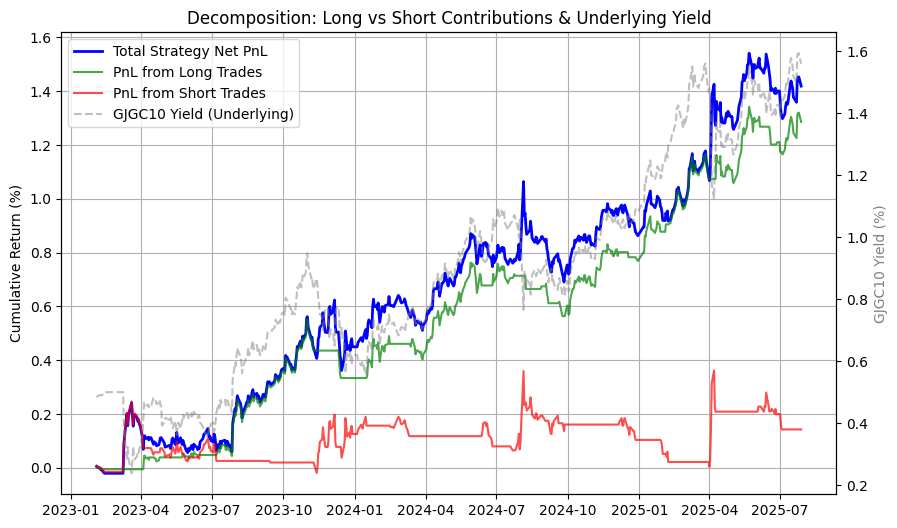

In [2]:
import pandas as pd
import numpy as np
from scipy.optimize import nnls
import matplotlib.pyplot as plt

# データの読み込み
df = pd.read_csv('債券複利データセット3.csv')
df['Date'] = pd.to_datetime(df['Unnamed: 0'])
df.set_index('Date', inplace=True)
prices_10 = df['GJGC10'].dropna().values
prices_30 = df['GJGC30'].dropna().values
dates = df['GJGC10'].dropna().index

K = 30
W_initial = 504
step = 21
D = np.triu(np.ones((K, K)))
dp_30 = np.diff(prices_30)

# OOSシグナルの生成 (Expanding Window)
signals_oos = np.full(len(prices_30), np.nan)

# 初期期間
dp_train_init = dp_30[:W_initial]
T_obs_init = len(dp_train_init) - K
y_init = dp_train_init[K:]
X_init = np.zeros((T_obs_init, K))
for j in range(1, K + 1):
    X_init[:, j-1] = dp_train_init[K-j : len(dp_train_init)-j]
XD_ext_init = np.hstack((X_init @ D, np.ones((T_obs_init, 1)), -np.ones((T_obs_init, 1))))
z_ext_init, _ = nnls(XD_ext_init, y_init)
beta_init = D @ z_ext_init[:-2]
for t in range(K, W_initial):
    signals_oos[t] = np.sum(beta_init * dp_30[t-K:t][::-1])

# ウォークフォワード期間
for t_start in range(W_initial, len(prices_30), step):
    t_end = min(t_start + step, len(prices_30))
    dp_train = dp_30[:t_start]
    T_obs = len(dp_train) - K
    y = dp_train[K:]
    X = np.zeros((T_obs, K))
    for j in range(1, K + 1):
        X[:, j-1] = dp_train[K-j : len(dp_train)-j]
    XD_ext = np.hstack((X @ D, np.ones((T_obs, 1)), -np.ones((T_obs, 1))))
    z_ext, _ = nnls(XD_ext, y)
    beta = D @ z_ext[:-2]
    for t_oos in range(t_start, t_end):
        recent_dp = dp_30[t_oos-K:t_oos][::-1]
        signals_oos[t_oos] = np.sum(beta * recent_dp)

# SMA15
sig_series = pd.Series(signals_oos)
smoothed_signals = sig_series.rolling(window=15).mean().values

# トレードシミュレーション (Long/Short分解)
weights = np.zeros(len(prices_10))
pnl_net = np.zeros(len(prices_10))
pnl_long = np.zeros(len(prices_10))
pnl_short = np.zeros(len(prices_10))

for t in range(W_initial, len(prices_10) - 1):
    G_t = smoothed_signals[t] if not np.isnan(smoothed_signals[t]) else signals_oos[t]

    if G_t > 1e-8:
        w_t = 1
    elif G_t < -1e-8:
        w_t = -1
    else:
        w_t = 0

    weights[t] = w_t
    w_prev = weights[t-1] if t > W_initial else 0
    cost = 0.005 if w_t != w_prev else 0

    ret = prices_10[t+1] - prices_10[t]
    net_ret = w_t * ret - cost
    pnl_net[t+1] = net_ret

    # LongとShortに分解して集計
    if w_t == 1:
        pnl_long[t+1] = net_ret
    elif w_t == -1:
        pnl_short[t+1] = net_ret

# OOS評価期間
oos_dates = dates[W_initial+1:]
oos_pnl = pnl_net[W_initial+1:]
oos_pnl_long = pnl_long[W_initial+1:]
oos_pnl_short = pnl_short[W_initial+1:]

# 単純なバイ・アンド・ホールド(ずっとLong)のリターン (原資産の推移)
benchmark_pnl = np.zeros(len(prices_10))
for t in range(W_initial, len(prices_10) - 1):
    benchmark_pnl[t+1] = prices_10[t+1] - prices_10[t]
oos_benchmark = benchmark_pnl[W_initial+1:]

# 結果の集計
print(f"Total Net TR: {np.sum(oos_pnl):.4f}")
print(f"  -> TR from Long Positions: {np.sum(oos_pnl_long):.4f}")
print(f"  -> TR from Short Positions: {np.sum(oos_pnl_short):.4f}")
print(f"Benchmark (Buy & Hold) TR: {np.sum(oos_benchmark):.4f}")

# 勝率の計算
win_long = np.sum(oos_pnl_long > 0)
loss_long = np.sum(oos_pnl_long < 0)
win_short = np.sum(oos_pnl_short > 0)
loss_short = np.sum(oos_pnl_short < 0)
print(f"Long Win Rate: {win_long / (win_long + loss_long) if (win_long + loss_long)>0 else 0:.2%}")
print(f"Short Win Rate: {win_short / (win_short + loss_short) if (win_short + loss_short)>0 else 0:.2%}")

# グラフのプロット
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(oos_dates, np.cumsum(oos_pnl), label='Total Strategy Net PnL', color='blue', linewidth=2)
ax1.plot(oos_dates, np.cumsum(oos_pnl_long), label='PnL from Long Trades', color='green', alpha=0.7)
ax1.plot(oos_dates, np.cumsum(oos_pnl_short), label='PnL from Short Trades', color='red', alpha=0.7)

# ベンチマーク(金利の推移)を右軸でプロット
ax2 = ax1.twinx()
ax2.plot(oos_dates, prices_10[W_initial+1:], label='GJGC10 Yield (Underlying)', color='grey', linestyle='dashed', alpha=0.5)
ax2.set_ylabel('GJGC10 Yield (%)', color='grey')

ax1.set_title('Decomposition: Long vs Short Contributions & Underlying Yield')
ax1.set_ylabel('Cumulative Return (%)')
ax1.grid(True)

# 凡例を統合
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.savefig('backtest_long_short.png')

In [3]:
import pandas as pd
import numpy as np
from scipy.optimize import nnls

def get_current_trend_signal(csv_path, new_yield=None, new_date=None, K=30, sma_window=15):
    """
    最新のGJGC30データから現在のトレンドシグナルと推奨ポジションを表示する関数

    Parameters:
    csv_path (str): CSVファイルのパス
    new_yield (float, optional): 当日の新しいGJGC30の利回り（CSV未追記の場合に指定）
    new_date (str, optional): 当日の日付（例: '2025-07-29'）
    K (int): 単調回帰の最大ラグ数 (デフォルト: 30)
    sma_window (int): シグナル平滑化の移動平均期間 (デフォルト: 15)
    """
    # 1. データの読み込み
    df = pd.read_csv(csv_path)
    df['Date'] = pd.to_datetime(df['Unnamed: 0'])
    df.set_index('Date', inplace=True)
    series_30 = df['GJGC30'].dropna().copy()

    # 2. 新しいデータが引数で渡された場合は末尾に追加
    if new_yield is not None:
        if new_date is None:
            next_date = series_30.index[-1] + pd.Timedelta(days=1)
        else:
            next_date = pd.to_datetime(new_date)
        series_30.loc[next_date] = new_yield

    prices = series_30.values
    dates = series_30.index
    dp = np.diff(prices)
    D = np.triu(np.ones((K, K)))

    # 3. 直近 sma_window 日分のシグナルを Expanding Window で計算
    recent_signals = []
    recent_dates = []

    start_t = len(prices) - sma_window
    for t in range(start_t, len(prices)):
        # 時点 t までに観測された全階差データを用いて単調回帰(NNLS)を実行
        dp_avail = dp[:t]
        T_obs = len(dp_avail) - K
        y = dp_avail[K:]
        X = np.zeros((T_obs, K))
        for j in range(1, K + 1):
            X[:, j-1] = dp_avail[K-j : len(dp_avail)-j]

        XD_ext = np.hstack((X @ D, np.ones((T_obs, 1)), -np.ones((T_obs, 1))))
        z_ext, _ = nnls(XD_ext, y)
        beta = D @ z_ext[:-2]

        # 時点 t の直近 K 個の階差から当日のシグナル G_t を算出
        recent_dp = dp[t-K:t][::-1]
        G_t = np.sum(beta * recent_dp)

        recent_signals.append(G_t)
        recent_dates.append(dates[t])

    # 4. 最新シグナルとSMA(15)の集計
    raw_signal = recent_signals[-1]
    sma_signal = np.mean(recent_signals)

    if sma_signal > 1e-8:
        position = "LONG (+1: 金利上昇予測)"
    elif sma_signal < -1e-8:
        position = "SHORT (-1: 金利低下予測)"
    else:
        position = "NEUTRAL (0: ポジションなし)"

    # 5. 結果の表示
    print(f"=== トレンドシグナル判定結果 ({recent_dates[-1].strftime('%Y-%m-%d')}) ===")
    print(f"最新 GJGC30 利回り      : {prices[-1]:.3f} % (前日比: {dp[-1]:+.3f} %)")
    print(f"当日 生シグナル (G_t)   : {raw_signal:+.6f} ({raw_signal*100:+.3f} bp)")
    print(f"平滑化シグナル (SMA{sma_window}) : {sma_signal:+.6f} ({sma_signal*100:+.3f} bp)")
    print(f"推奨ポジション          : {position}")
    print("-" * 52)
    print("【直近5日間の生シグナル推移】")
    for d, s in zip(recent_dates[-5:], recent_signals[-5:]):
        print(f"  {d.strftime('%Y-%m-%d')}: {s:+.6f} ({s*100:+.3f} bp)")

    return raw_signal, sma_signal, beta


# ==========================================
# 実行方法（以下のいずれかの方法で実行してください）
# ==========================================

# パターンA：CSVに追記せず、当日の数値を直接入力して判定する場合（例: 当日利回りが 2.990% のとき）
raw_sig, sma_sig, latest_beta = get_current_trend_signal(
    csv_path='債券複利データセット3.csv',
    new_yield=2.990,
    new_date='2025-07-29'
)

# パターンB：すでにCSVファイルに最新行を追記・保存している場合
# raw_sig, sma_sig, latest_beta = get_current_trend_signal('債券複利データセット3.csv')

=== トレンドシグナル判定結果 (2025-07-29) ===
最新 GJGC30 利回り      : 2.990 % (前日比: +0.015 %)
当日 生シグナル (G_t)   : +0.001521 (+0.152 bp)
平滑化シグナル (SMA15) : +0.000433 (+0.043 bp)
推奨ポジション          : LONG (+1: 金利上昇予測)
----------------------------------------------------
【直近5日間の生シグナル推移】
  2025-07-23: +0.003956 (+0.396 bp)
  2025-07-24: -0.002700 (-0.270 bp)
  2025-07-25: -0.002826 (-0.283 bp)
  2025-07-28: -0.003162 (-0.316 bp)
  2025-07-29: +0.001521 (+0.152 bp)


In [ ]:
import pandas as pd
import numpy as np
from scipy.optimize import nnls
import matplotlib.pyplot as plt

# 1. データの読み込み
df = pd.read_csv('債券複利データセット3.csv')
df['Date'] = pd.to_datetime(df['Unnamed: 0'])
df.set_index('Date', inplace=True)

prices_10 = df['GJGC10'].dropna().values
prices_20 = df['GJGC20'].dropna().values
prices_30 = df['GJGC30'].dropna().values
prices_40 = df['GJGC40'].dropna().values
dates = df['GJGC10'].dropna().index

K = 30
W_initial = 504
step = 21
D = np.triu(np.ones((K, K)))

# 2. 外れ値クリッピング付き Expanding Window シグナル生成関数
def get_robust_expanding_signals(prices, clip_quantile=0.01):
    dp = np.diff(prices)
    signals_oos = np.full(len(prices), np.nan)

    # (準備) 初期期間の計算
    dp_train_init = dp[:W_initial].copy()
    if clip_quantile is not None:
        low, high = np.quantile(dp_train_init, [clip_quantile, 1 - clip_quantile])
        dp_train_init = np.clip(dp_train_init, low, high)

    T_obs_init = len(dp_train_init) - K
    y_init = dp_train_init[K:]
    X_init = np.zeros((T_obs_init, K))
    for j in range(1, K + 1):
        X_init[:, j-1] = dp_train_init[K-j : len(dp_train_init)-j]
    XD_ext_init = np.hstack((X_init @ D, np.ones((T_obs_init, 1)), -np.ones((T_obs_init, 1))))
    z_ext_init, _ = nnls(XD_ext_init, y_init)
    beta_init = D @ z_ext_init[:-2]

    for t in range(K, W_initial):
        signals_oos[t] = np.sum(beta_init * dp[t-K:t][::-1])

    # ウォークフォワード (Expanding Window)
    for t_start in range(W_initial, len(prices), step):
        t_end = min(t_start + step, len(prices))
        dp_train = dp[:t_start].copy()

        # 【施策②】上下1%の外れ値をクリッピングしてロバスト化
        if clip_quantile is not None:
            low, high = np.quantile(dp_train, [clip_quantile, 1 - clip_quantile])
            dp_train = np.clip(dp_train, low, high)

        T_obs = len(dp_train) - K
        y = dp_train[K:]
        X = np.zeros((T_obs, K))
        for j in range(1, K + 1):
            X[:, j-1] = dp_train[K-j : len(dp_train)-j]

        XD_ext = np.hstack((X @ D, np.ones((T_obs, 1)), -np.ones((T_obs, 1))))
        z_ext, _ = nnls(XD_ext, y)
        beta = D @ z_ext[:-2]

        for t_oos in range(t_start, t_end):
            recent_dp = dp[t_oos-K:t_oos][::-1]
            if clip_quantile is not None:
                recent_dp = np.clip(recent_dp, low, high)
            signals_oos[t_oos] = np.sum(beta * recent_dp)

    return signals_oos

# 3. 【施策①】20年・30年・40年債それぞれのロバスト・シグナルを算出
sig_20 = get_robust_expanding_signals(prices_20, clip_quantile=0.01)
sig_30 = get_robust_expanding_signals(prices_30, clip_quantile=0.01)
sig_40 = get_robust_expanding_signals(prices_40, clip_quantile=0.01)

# それぞれSMA(15)で平滑化し、個別判定 (+1, -1, 0) を作成
def get_individual_vote(sig, window=15):
    sma = pd.Series(sig).rolling(window=window).mean().values
    return np.where(sma > 1e-8, 1, np.where(sma < -1e-8, -1, 0))

vote_20 = get_individual_vote(sig_20, 15)
vote_30 = get_individual_vote(sig_30, 15)
vote_40 = get_individual_vote(sig_40, 15)

# 3年限の多数決（合計の符号）で最終ウェイトを決定
weights = np.sign(vote_20 + vote_30 + vote_40)

# 4. GJGC10でのバックテスト実行 (コスト0.5bp)
pnl_net = np.zeros(len(prices_10))
for t in range(W_initial, len(prices_10) - 1):
    w_t = weights[t]
    w_prev = weights[t-1] if t > W_initial else 0
    cost = 0.005 if w_t != w_prev else 0
    ret = prices_10[t+1] - prices_10[t]
    pnl_net[t+1] = w_t * ret - cost

# 5. パフォーマンス評価
oos_net = pnl_net[W_initial+1:]
oos_dates = dates[W_initial+1:]
cum_net = np.cumsum(oos_net)

AR = 252 * np.mean(oos_net)
Risk = np.sqrt(252) * np.std(oos_net)
RR = AR / Risk if Risk > 0 else 0
MaxDD = -np.min(cum_net - np.maximum.accumulate(cum_net))
CR = AR / MaxDD if MaxDD > 0 else 0
TR = np.sum(oos_net)
trades = np.sum(np.abs(np.diff(weights[W_initial:])) > 0)

print(f"=== Multi-Tenor (20Y/30Y/40Y) + 1% Winsorization ===")
print(f"Trades: {trades}")
print(f"Net TR: {TR:.4f}%, AR: {AR:.4f}%, R/R: {RR:.4f}, MaxDD: {MaxDD:.4f}%, CR: {CR:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(oos_dates, cum_net, label='Robust Ensemble (20Y/30Y/40Y Vote + 1% Clip)', color='green', linewidth=2)
plt.title('Robust Cross-Asset Strategy on GJGC10')
plt.ylabel('Cumulative Return (%)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
=== 頑健化トレンドシグナル判定結果 (2025-07-29) ===
[設定: K=30, SMA=15, 外れ値クリッピング=1.0%]
------------------------------------------------------------
【1. GJGC30 (30年債) ロバスト単独判定】
  最新 GJGC30 利回り  : 2.990 % (前日比: +0.015 %)
  当日 生シグナル(G_t): +0.001623 (+0.162 bp)
  平滑化 (SMA15)      : +0.000412 (+0.041 bp)
  30年債 単独推奨     : LONG (+1: 金利上昇予測)
------------------------------------------------------------
【2. マルチ年限アンサンブル (20Y・30Y・40Y 多数決)】
  GJGC20 (20年債) [2025-07-28]: SMA15 = +0.082 bp -> 判定: +1 (LONG)
  GJGC30 (30年債) [2025-07-29]: SMA15 = +0.041 bp -> 判定: +1 (LONG)
  GJGC40 (40年債) [2025-07-28]: SMA15 = +0.077 bp -> 判定: +1 (LONG)

  >>> 最終推奨ポジション (多数決): LONG (+1: 金利上昇予測 / 債券売り)
------------------------------------------------------------
【GJGC30 直近5日間のロバスト生シグナル推移】
  2025-07-23: +0.004225 (+0.422 bp)
  2025-07-24: -0.002877 (-0.288 bp)
  2025-07-25: -0.003015 (-0.302 bp)
  2025-07-28: -0.003378 (-0.338 bp)
  2025-07-29: +0.001623 (+0.162 bp)